In [20]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_csv("../data/ecommerce_sales_data.csv")

# Display first 5 rows
df.head()

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
0,2024-12-31,Printer,Office,North,4,3640,348.93
1,2022-11-27,Mouse,Accessories,East,7,1197,106.53
2,2022-05-11,Tablet,Electronics,South,5,5865,502.73
3,2024-03-16,Mouse,Accessories,South,2,786,202.87
4,2022-09-10,Mouse,Accessories,West,1,509,103.28


### Check Missing Values

In [3]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
Order Date      0
Product Name    0
Category        0
Region          0
Quantity        0
Sales           0
Profit          0
dtype: int64


### Check Duplicate Records

In [5]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


### Check Data Types

In [6]:
# Display current data types

print(df.dtypes)

Order Date       object
Product Name     object
Category         object
Region           object
Quantity          int64
Sales             int64
Profit          float64
dtype: object


In [7]:
# Check numeric columns

numeric_columns = ['Quantity', 'Sales', 'Profit']

for column in numeric_columns:

    print(column, ":", df[column].dtype)

Quantity : int64
Sales : int64
Profit : float64


### Check Invalid Values

In [8]:
# Check zero or negative quantity

invalid_quantity = df[df['Quantity'] <= 0]

print("Invalid Quantity Records:", len(invalid_quantity))

invalid_quantity.head()

Invalid Quantity Records: 0


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit


In [9]:
# Check zero or negative sales

invalid_sales = df[df['Sales'] <= 0]

print("Invalid Sales Records:", len(invalid_sales))

invalid_sales.head()

Invalid Sales Records: 0


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit


In [10]:
# Check negative profit

negative_profit = df[df['Profit'] < 0]

print("Negative Profit Records:", len(negative_profit))

negative_profit.head()

Negative Profit Records: 0


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit


### Check Inconsistent Text Values

In [11]:
# Check leading and trailing spaces

text_columns = ['Product Name', 'Category', 'Region']

for column in text_columns:

    space_count = (
        df[column]
        .dropna()
        .astype(str)
        .ne(df[column].dropna().astype(str).str.strip())
        .sum()
    )

    print(f"{column}: {space_count} records with extra spaces")

Product Name: 0 records with extra spaces
Category: 0 records with extra spaces
Region: 0 records with extra spaces


### Validate Date Column

In [12]:
# Convert dates temporarily for assessment

date_check = pd.to_datetime(df['Order Date'], errors='coerce')

print("Date Column Assessment")

print("Invalid Dates:", date_check.isnull().sum())

print("Minimum Date:", date_check.min())

print("Maximum Date:", date_check.max())

Date Column Assessment
Invalid Dates: 0
Minimum Date: 2022-01-01 00:00:00
Maximum Date: 2024-12-31 00:00:00


In [13]:
# Expected date range

start_date = pd.Timestamp('2022-01-01')

end_date = pd.Timestamp('2024-12-31')

# Find dates outside the expected range

invalid_dates = df[
    (date_check < start_date) |
    (date_check > end_date)
]

print("Dates Outside Expected Range:", len(invalid_dates))

invalid_dates.head()

Dates Outside Expected Range: 0


,Order Date,Product Name,Category,Region,Quantity,Sales,Profit


### Outlier Detection

In [16]:
# Function to detect outliers using IQR

def detect_outliers(data, column):

    Q1 = data[column].quantile(0.25)

    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR

    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    print("Column:", column)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outliers:", len(outliers))
    

    return outliers

In [17]:
quantity_outliers = detect_outliers(df, 'Quantity')

Column: Quantity
Lower Limit: -3.0
Upper Limit: 13.0
Outliers: 0


In [18]:
sales_outliers = detect_outliers(df, 'Sales')

Column: Sales
Lower Limit: -4181.75
Upper Limit: 9768.25
Outliers: 35


In [19]:
profit_outliers = detect_outliers(df, 'Profit')

Column: Profit
Lower Limit: -696.95
Upper Limit: 1584.77
Outliers: 184


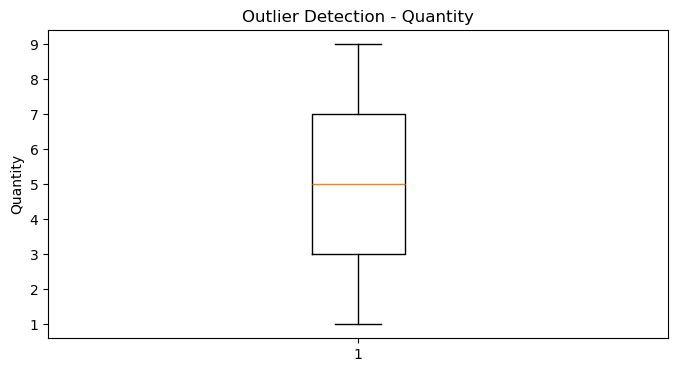

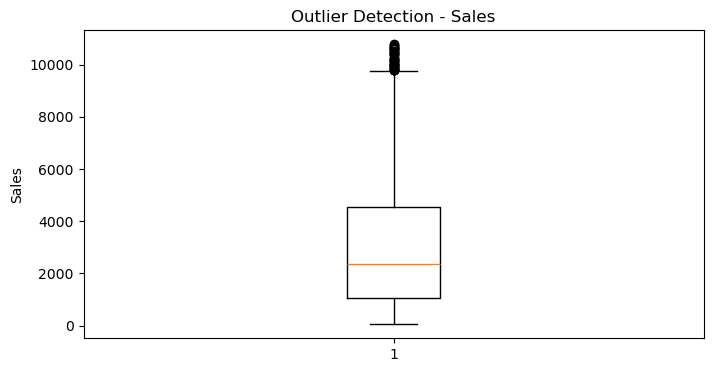

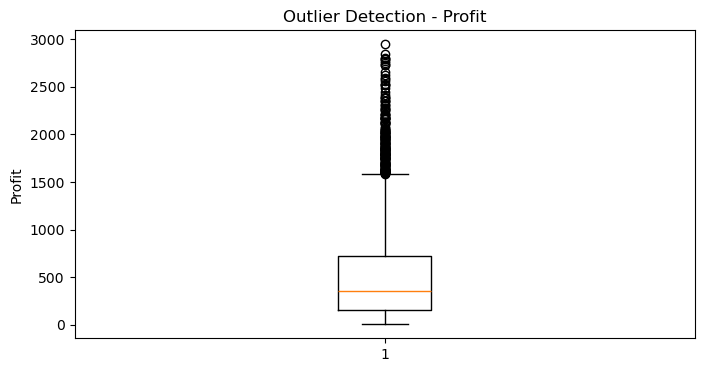

In [21]:
# Create boxplots

columns = ['Quantity', 'Sales', 'Profit']

for column in columns:

    plt.figure(figsize=(8, 4))

    plt.boxplot(df[column].dropna())

    plt.title(f"Outlier Detection - {column}")

    plt.ylabel(column)

    plt.show()

### Statistical Summary

In [22]:
# Generate statistical summary

df.describe()

,Quantity,Sales,Profit
count,3500.000000,3500.000000,3500.000000
mean,4.931714,3047.966000,527.047203
std,2.575895,2440.213237,504.139732
min,1.000000,51.000000,6.970000
25%,3.000000,1049.500000,158.695000
50%,5.000000,2350.500000,361.070000
75%,7.000000,4537.000000,729.125000
max,9.000000,10782.000000,2946.930000


In [23]:
# Statistical summary of categorical columns

df.describe(include='object')

,Order Date,Product Name,Category,Region
count,3500,3500,3500,3500
unique,1051,10,3,4
top,2023-08-12,Monitor,Electronics,West
freq,11,364,1742,898


## Final Data Quality Report

In [ ]:
# Create data quality summary

quantity_outlier_count = len(quantity_outliers)
sales_outlier_count = len(sales_outliers)
profit_outlier_count = len(profit_outliers)

# Create data quality summary

quality_report = pd.DataFrame({

    'Check': [
        'Total Records',
        'Total Columns',
        'Missing Values',
        'Duplicate Records',
        'Invalid Dates',
        'Invalid Quantity',
        'Invalid Sales',
        'Negative Profit Records',
        'Quantity Outliers',
        'Sales Outliers',
        'Profit Outliers'
    ],

    'Result': [

        len(df),
        len(df.columns),
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        date_check.isnull().sum(),
        (df['Quantity'] <= 0).sum(),
        (df['Sales'] <= 0).sum(),
        (df['Profit'] < 0).sum(),
        quantity_outlier_count,
        sales_outlier_count,
        profit_outlier_count

    ]

})

# Display final report

quality_report

,Check,Result
0,Total Records,3500
1,Total Columns,7
2,Missing Values,0
3,Duplicate Records,0
4,Invalid Dates,0
5,Invalid Quantity,0
6,Invalid Sales,0
7,Negative Profit Records,0
8,Quantity Outliers,0
9,Sales Outliers,35
